# Unit 3 – Polynomial regression
**Aim:** show that a linear model under-fits curved data, that a higher-degree polynomial can over-fit, and how the train/test gap reveals this.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
np.random.seed(42)
plt.rcParams['figure.figsize'] = (6, 4)
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

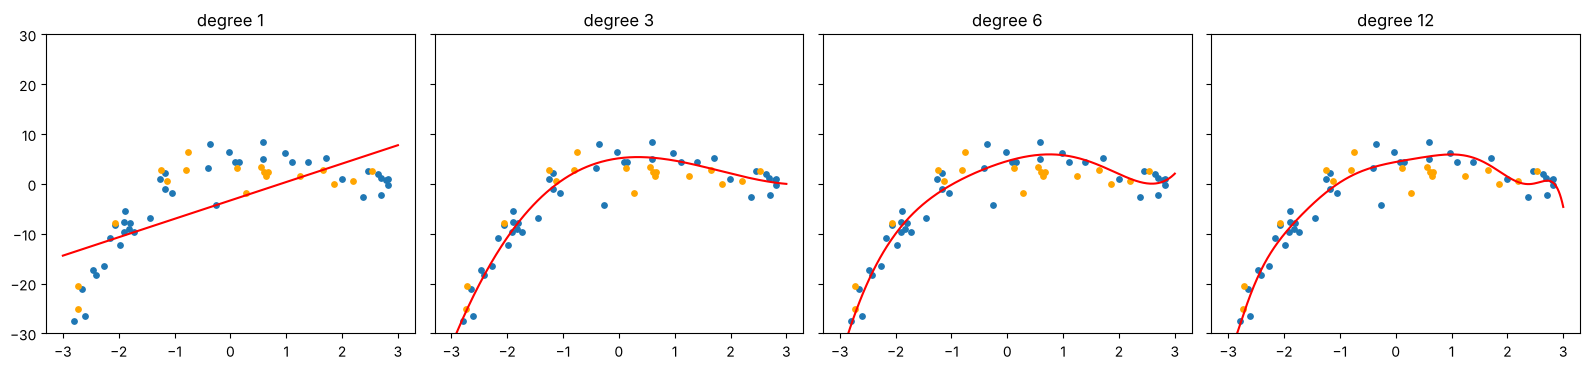

In [2]:
rng = np.random.RandomState(42)
x = np.sort(rng.uniform(-3, 3, 60))
y = 0.5 * x ** 3 - 2 * x ** 2 + x + 4 + rng.normal(0, 3, x.size)      # true relationship is cubic
X = x.reshape(-1, 1)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=.3, random_state=1)

xx = np.linspace(-3, 3, 300).reshape(-1, 1)
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), sharey=True)
rows = []
for ax, d in zip(axes, (1, 3, 6, 12)):
    pipe = make_pipeline(PolynomialFeatures(d), LinearRegression()).fit(Xtr, ytr)
    ax.scatter(Xtr, ytr, s=15); ax.scatter(Xte, yte, s=15, c='orange')
    ax.plot(xx, pipe.predict(xx), 'r'); ax.set_title(f'degree {d}'); ax.set_ylim(-30, 30)
plt.tight_layout(); plt.show()

,degree,train_MSE,test_MSE,test_R2
0,1,49.92,41.42,0.378
1,2,9.00,19.25,0.711
2,3,6.16,9.92,0.851
3,4,5.98,10.06,0.849
4,5,5.62,12.64,0.810
5,6,5.61,12.66,0.810
6,7,5.60,12.42,0.814
7,8,5.54,12.05,0.819
8,9,5.53,11.69,0.825
9,10,5.51,11.76,0.824


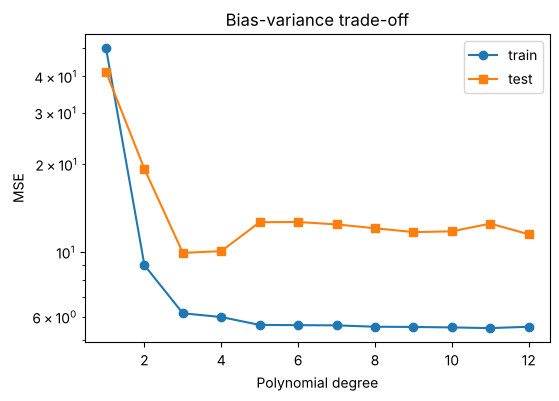

Best degree on test MSE: 3


In [3]:
rows = []
for d in range(1, 13):
    pipe = make_pipeline(PolynomialFeatures(d), LinearRegression()).fit(Xtr, ytr)
    rows.append({'degree': d,
                 'train_MSE': round(mean_squared_error(ytr, pipe.predict(Xtr)), 2),
                 'test_MSE': round(mean_squared_error(yte, pipe.predict(Xte)), 2),
                 'test_R2': round(r2_score(yte, pipe.predict(Xte)), 3)})
table = pd.DataFrame(rows); display(table)
plt.plot(table.degree, table.train_MSE, 'o-', label='train'); plt.plot(table.degree, table.test_MSE, 's-', label='test')
plt.yscale('log'); plt.xlabel('Polynomial degree'); plt.ylabel('MSE'); plt.legend(); plt.title('Bias-variance trade-off'); plt.show()
print('Best degree on test MSE:', int(table.loc[table.test_MSE.idxmin(), 'degree']))

## Observations
* The true curve is cubic. A straight line (degree 1) under-fits: test MSE 41.42, R² 0.378.
* Degree 3 matched the true form and gave the lowest test MSE (9.92, R² 0.851).
* Higher degrees kept lowering training MSE slightly (down to about 5.5) while test MSE did not improve (11.5–12.7), so the gap between train and test widened – the signature of over-fitting.
* Model complexity should be chosen on held-out data, not on training error.